In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [13]:
df = pd.read_csv(
    '/content/drive/MyDrive/Bank Marketing EDA/data/raw/bank-full.csv',
    sep=';'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Bank Marketing Campaign & Customer Segmentation Analysis

## 1. Introduction

### Objective
The objective of this project is to analyse customer and campaign characteristics to understand patterns associated with term deposit subscriptions.

### Dataset
The dataset is obtained from the UCI Machine Learning Repository – Bank Marketing Dataset.

### Tools & Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### 2. Data Understanding

In [16]:
display(df.head())

df.info()

display(df.describe())

display(df.describe(include='object'))

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [17]:
print("Columns in the dataset:")
print(df.columns.tolist())

print("\nDataset shape:", df.shape)

Columns in the dataset:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset shape: (45211, 17)


In [18]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())


print("\nData Types:")
print(df.dtypes)

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate Records: 0

Data Types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object


In [19]:
# Unique values in categorical columns
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


job:
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

marital:
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

education:
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

default:
default
no     44396
yes      815
Name: count, dtype: int64

housing:
housing
yes    25130
no     20081
Name: count, dtype: int64

loan:
loan
no     37967
yes     7244
Name: count, dtype: int64

contact:
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

month:
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Nam

In [20]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [21]:
numerical_cols = df.select_dtypes(include='number').columns

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Outlier count:", len(outliers))


age
Lower bound: 10.5
Upper bound: 70.5
Outlier count: 487

balance
Lower bound: -1962.0
Upper bound: 3462.0
Outlier count: 4729

day
Lower bound: -11.5
Upper bound: 40.5
Outlier count: 0

duration
Lower bound: -221.0
Upper bound: 643.0
Outlier count: 3235

campaign
Lower bound: -2.0
Upper bound: 6.0
Outlier count: 3064

pdays
Lower bound: -1.0
Upper bound: -1.0
Outlier count: 8257

previous
Lower bound: 0.0
Upper bound: 0.0
Outlier count: 8257


In [22]:
#Important numerical ranges

print("Age below 18:", (df['age'] < 18).sum())
print("Negative campaign contacts:", (df['campaign'] < 1).sum())
print("Negative previous contacts:", (df['previous'] < 0).sum())
print("Invalid day values:", (~df['day'].between(1, 31)).sum())
print("Negative call durations:", (df['duration'] < 0).sum())

Age below 18: 0
Negative campaign contacts: 0
Negative previous contacts: 0
Invalid day values: 0
Negative call durations: 0


### Data Cleaning Summary

- **Missing values:** No missing values were found.
- **Duplicate records:** No duplicate rows were found.
- **Data types:** Numerical and categorical columns have appropriate data types.
- **Unknown categories:** Retained as separate categories because they represent unavailable or unreported information.
- **Outliers:** Retained because the extreme values may represent genuine customer characteristics or campaign activity.
- **Special values:** The value `-1` in `pdays` was retained because it indicates that the customer was not previously contacted.
- **Data validation:** No invalid age, campaign contact, previous contact, day, or call duration values were found.

**Conclusion:** No records needed to be removed or modified. The original dataset is retained for exploratory data analysis.

In [23]:
# Subscription count and percentage

subscription_counts = df['y'].value_counts()

subscription_percentage = (
    df['y'].value_counts(normalize=True) * 100
)

print("Subscription Counts:")
print(subscription_counts)

print("\nSubscription Percentage:")
print(subscription_percentage.round(2))

Subscription Counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription Percentage:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


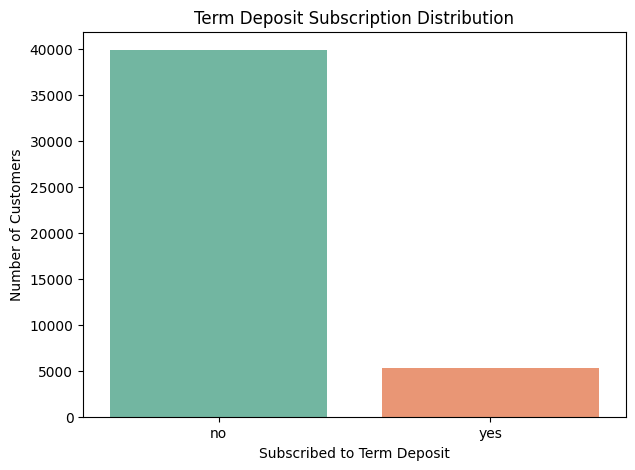

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y', hue='y',
              palette='Set2', legend=False)

plt.title('Term Deposit Subscription Distribution')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')

plt.show()

### Q1. What percentage of customers subscribed?

The dataset contains 45,211 customers, out of which 5,289 subscribed to the term deposit, while 39,922 did not.

The overall subscription rate is **11.70%**, whereas 88.30% of customers did not subscribe.

**Insight:** The campaign recorded a relatively low overall subscription rate. This highlights the importance of identifying customer segments that are more likely to respond positively to future marketing campaigns.

In [31]:
bins = [17, 30, 40, 50, 60, 100]
labels = ['18-30', '31-40', '41-50', '51-60', '60+']

df['age_group'] = pd.cut(
    df['age'],
    bins=bins,
    labels=labels
)

# Calculate customer count and subscription rate
age_analysis = df.groupby('age_group', observed=True).agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

display(age_analysis.round(2))


,age_group,total_customers,subscribers,subscription_rate
0,18-30,7030,1145,16.29
1,31-40,17687,1812,10.24
2,41-50,11239,1019,9.07
3,51-60,8067,811,10.05
4,60+,1188,502,42.26


In [29]:
df['age_group'] = df['age_group'].cat.rename_categories(
    {'60+': '61+'}
)

age_analysis['age_group'] = age_analysis['age_group'].replace(
    {'60+': '61+'}
)

/tmp/ipykernel_950/3299799035.py:5: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  age_analysis['age_group'] = age_analysis['age_group'].replace(


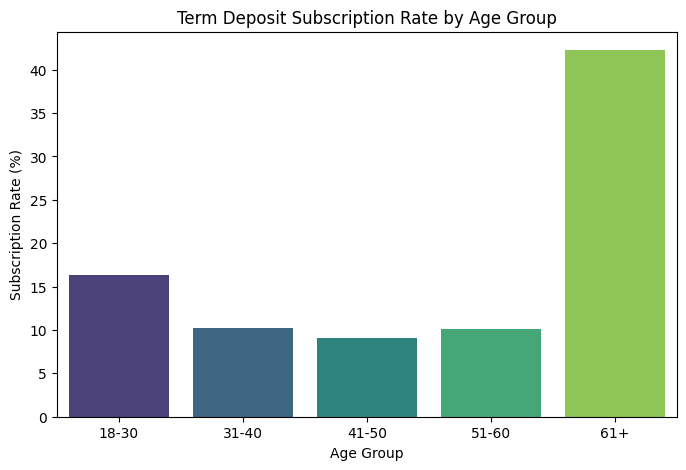

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_analysis,
    x='age_group',
    y='subscription_rate',
    hue='age_group',
    palette='viridis',
    legend=False
)

plt.title('Term Deposit Subscription Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Subscription Rate (%)')

plt.show()

### Q2. Which age groups are more likely to subscribe?

Customers aged 61 and above demonstrate the highest term deposit subscription rate at 42.26%, followed by customers aged 18–30 at 16.29%. The 41–50 age group records the lowest subscription rate at 9.07%.

**Insight:** Older customers may be a promising target segment for future marketing campaigns. However, the 61+ group has a relatively smaller sample size, so this finding should be interpreted cautiously.

In [32]:
job_analysis = df.groupby('job').agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

job_analysis = job_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

display(job_analysis.round(2))

,job,total_customers,subscribers,subscription_rate
8,student,938,269,28.68
5,retired,2264,516,22.79
10,unemployed,1303,202,15.50
4,management,9458,1301,13.76
0,admin.,5171,631,12.20
6,self-employed,1579,187,11.84
11,unknown,288,34,11.81
9,technician,7597,840,11.06
7,services,4154,369,8.88
3,housemaid,1240,109,8.79


### Q3. Does job type influence subscription?

The analysis shows considerable variation in subscription rates across different job categories.

Students have the highest subscription rate at 28.68%, followed by retired customers at 22.79%. In contrast, blue-collar workers have the lowest subscription rate at 7.27%.

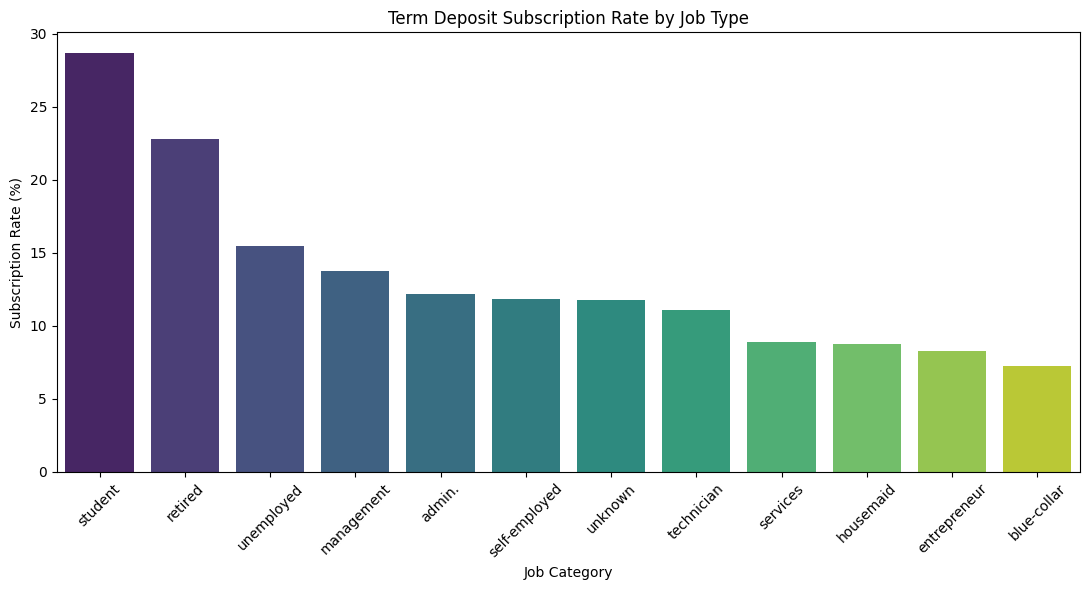

In [33]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=job_analysis,
    x='job',
    y='subscription_rate',
    hue='job',
    palette='viridis',
    legend=False
)

plt.title('Term Deposit Subscription Rate by Job Type')
plt.xlabel('Job Category')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [34]:
education_analysis = df.groupby('education').agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

education_analysis = education_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

display(education_analysis.round(2))

,education,total_customers,subscribers,subscription_rate
2,tertiary,13301,1996,15.01
3,unknown,1857,252,13.57
1,secondary,23202,2450,10.56
0,primary,6851,591,8.63


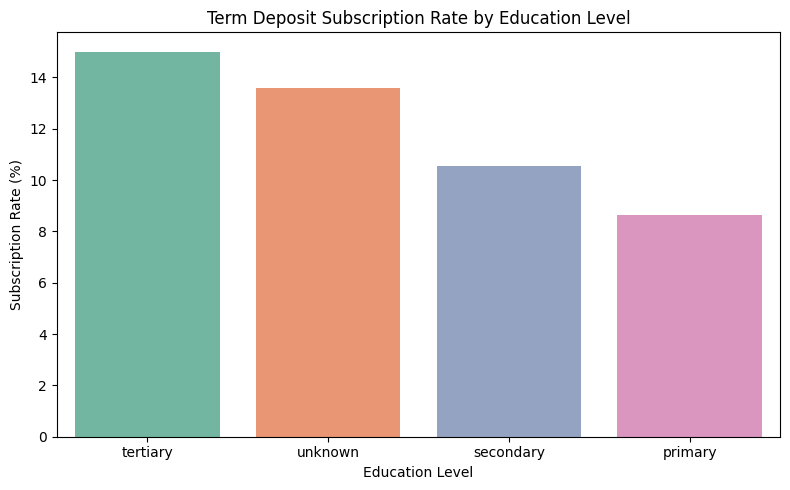

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=education_analysis,
    x='education',
    y='subscription_rate',
    hue='education',
    palette='Set2',
    legend=False
)

plt.title('Term Deposit Subscription Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

### Q4. Does education level influence customer response?

The analysis shows differences in term deposit subscription rates across education levels. Customers with tertiary education have the highest subscription rate at 15.01%, followed by customers with unknown education information at 13.57%.

Customers with secondary education have a subscription rate of 10.56%, while those with primary education have the lowest rate at 8.63%.


In [36]:
marital_analysis = df.groupby('marital').agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

marital_analysis = marital_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

display(marital_analysis.round(2))

,marital,total_customers,subscribers,subscription_rate
2,single,12790,1912,14.95
0,divorced,5207,622,11.95
1,married,27214,2755,10.12


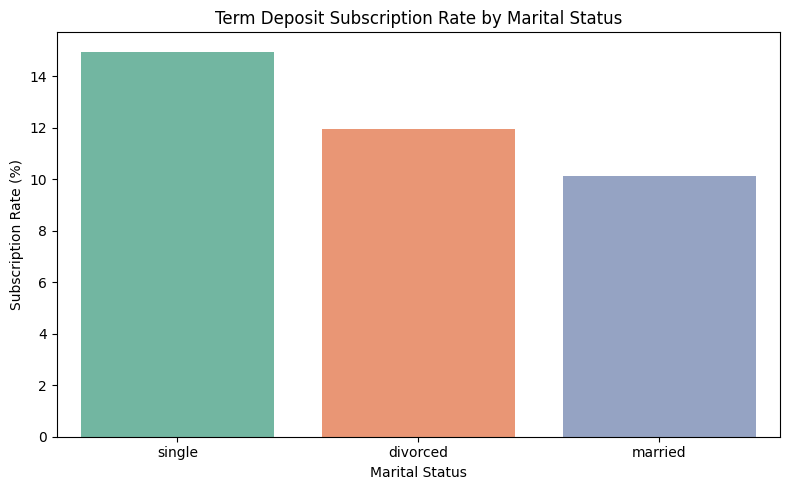

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=marital_analysis,
    x='marital',
    y='subscription_rate',
    hue='marital',
    palette='Set2',
    legend=False
)

plt.title('Term Deposit Subscription Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

### Q5. Does marital status relate to subscription?

Single customers have the highest subscription rate at 14.95%, followed by divorced customers at 11.95%. Married customers have the lowest rate at 10.12%.

In [38]:
balance_analysis = df.groupby('y')['balance'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

display(balance_analysis)

,count,mean,median,min,max
y,,,,,
no,39922,1303.71,417.0,-8019,102127
yes,5289,1804.27,733.0,-3058,81204


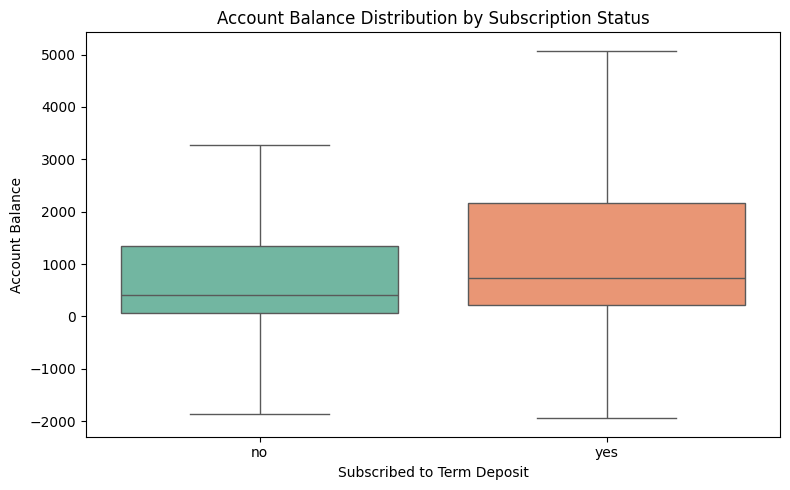

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='y',
    y='balance',
    hue='y',
    palette='Set2',
    showfliers=False,
    legend=False
)

plt.title('Account Balance Distribution by Subscription Status')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Account Balance')

plt.tight_layout()
plt.show()

### Q6. Does account balance differ between subscribers and non-subscribers?

Customers who subscribed had a higher average account balance (1,804.27) than non-subscribers (1,303.71). Their median balance was also higher (733 compared to 417), suggesting that subscribers generally maintained higher account balances.

In [41]:
campaign_analysis = df.groupby('campaign').agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

display(campaign_analysis.round(2))

,campaign,total_customers,subscribers,subscription_rate
0,1,17544,2561,14.60
1,2,12505,1401,11.20
2,3,5521,618,11.19
3,4,3522,317,9.00
4,5,1764,139,7.88
5,6,1291,92,7.13
6,7,735,47,6.39
7,8,540,32,5.93
8,9,327,21,6.42
9,10,266,14,5.26


In [42]:
df['campaign_group'] = pd.cut(
    df['campaign'],
    bins=[0, 1, 2, 3, 4, float('inf')],
    labels=['1', '2', '3', '4', '5+']
)

In [43]:
campaign_group_analysis = df.groupby(
    'campaign_group', observed=True
).agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

display(campaign_group_analysis.round(2))

,campaign_group,total_customers,subscribers,subscription_rate
0,1,17544,2561,14.60
1,2,12505,1401,11.20
2,3,5521,618,11.19
3,4,3522,317,9.00
4,5+,6119,392,6.41


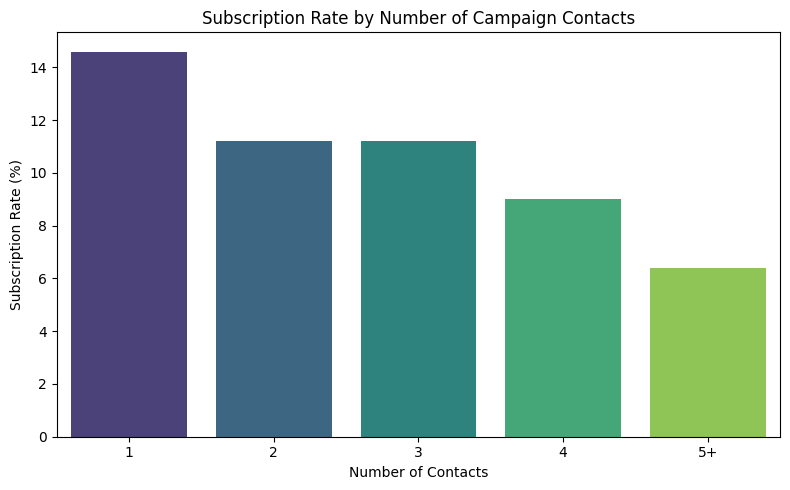

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=campaign_group_analysis,
    x='campaign_group',
    y='subscription_rate',
    hue='campaign_group',
    palette='viridis',
    legend=False
)

plt.title('Subscription Rate by Number of Campaign Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

### Q7. How does the number of campaign contacts affect subscription?

Customers contacted once have the highest subscription rate (14.60%), while those contacted five or more times have the lowest rate (6.41%). This suggests that repeated contact is associated with lower subscription rates.

In [45]:
contact_analysis = df.groupby('contact').agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

contact_analysis = contact_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

display(contact_analysis.round(2))

,contact,total_customers,subscribers,subscription_rate
0,cellular,29285,4369,14.92
1,telephone,2906,390,13.42
2,unknown,13020,530,4.07


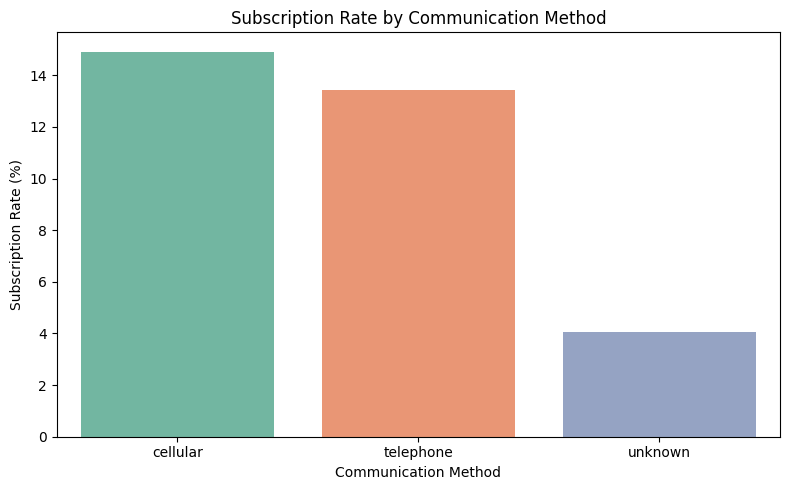

In [46]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=contact_analysis,
    x='contact',
    y='subscription_rate',
    hue='contact',
    palette='Set2',
    legend=False
)

plt.title('Subscription Rate by Communication Method')
plt.xlabel('Communication Method')
plt.ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

### Q8. Which communication method appears most effective?

Cellular communication has the highest subscription rate at 14.92%, followed by telephone at 13.42%. Customers with unknown communication methods have the lowest rate at 4.07%.

In [47]:
previous_analysis = df.groupby('poutcome').agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

previous_analysis = previous_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

display(previous_analysis.round(2))

,poutcome,total_customers,subscribers,subscription_rate
2,success,1511,978,64.73
1,other,1840,307,16.68
0,failure,4901,618,12.61
3,unknown,36959,3386,9.16


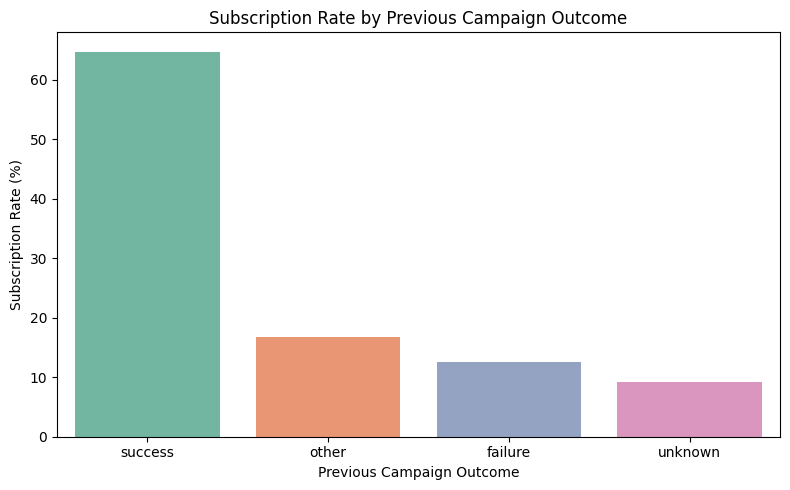

In [48]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=previous_analysis,
    x='poutcome',
    y='subscription_rate',
    hue='poutcome',
    palette='Set2',
    legend=False
)

plt.title('Subscription Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')

plt.tight_layout()
plt.show()

### Q9. Does previous campaign history relate to the current outcome?

Customers whose previous campaign was successful have the highest current subscription rate at 64.73%. Customers with unknown previous outcomes have the lowest rate at 9.16%.

In [49]:
segment_analysis = df.groupby(
    ['age_group', 'job', 'marital'],
    observed=True
).agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reset_index()

# Retain segments with at least 100 customers
segment_analysis = segment_analysis[
    segment_analysis['total_customers'] >= 100
]

segment_analysis = segment_analysis.sort_values(
    by='subscription_rate',
    ascending=False
)

display(segment_analysis.head(10).round(2))

,age_group,job,marital,total_customers,subscribers,subscription_rate
151,60+,retired,divorced,164,76,46.34
152,60+,retired,married,686,291,42.42
24,18-30,student,single,744,232,31.18
18,18-30,self-employed,single,175,41,23.43
14,18-30,management,single,870,194,22.30
30,18-30,unemployed,single,141,31,21.99
65,31-40,unemployed,single,189,37,19.58
59,31-40,student,single,127,24,18.90
119,51-60,retired,divorced,235,44,18.72
53,31-40,self-employed,single,209,37,17.70


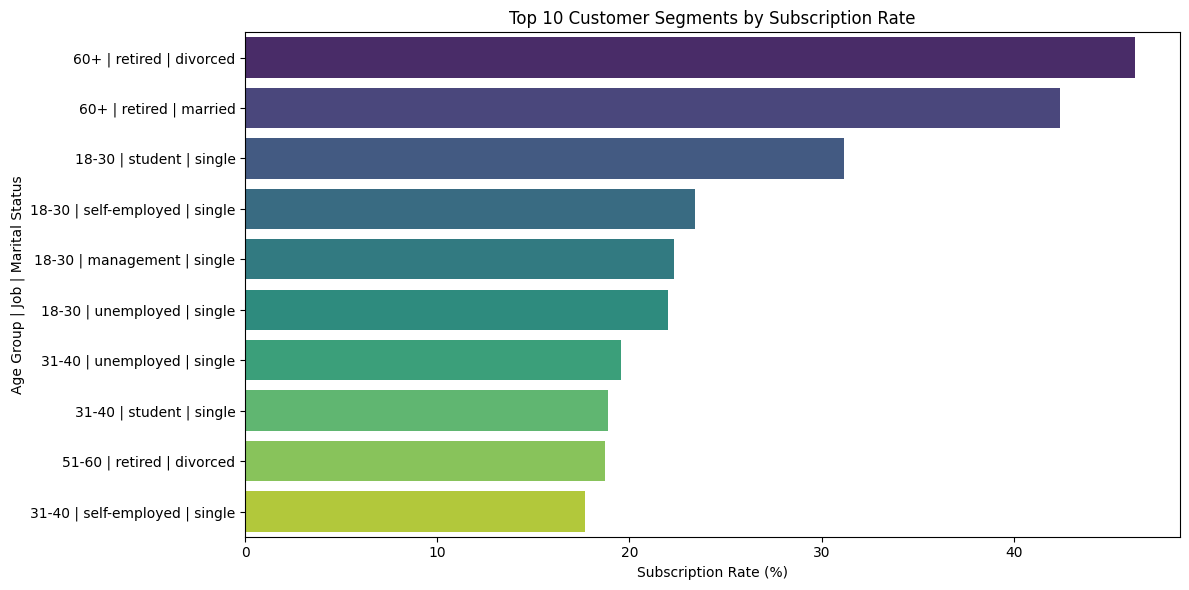

In [51]:
top_segments = segment_analysis.head(10).copy()

top_segments['segment'] = (
    top_segments['age_group'].astype(str) + ' | ' +
    top_segments['job'] + ' | ' +
    top_segments['marital']
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_segments,
    x='subscription_rate',
    y='segment',
    hue='segment',
    palette='viridis',
    legend=False
)

plt.title('Top 10 Customer Segments by Subscription Rate')
plt.xlabel('Subscription Rate (%)')
plt.ylabel('Age Group | Job | Marital Status')

plt.tight_layout()
plt.show()

### Q10. Which customer segments show higher subscription rates?

Retired customers aged 61+ show the highest subscription rates (46.34% among divorced and 42.42% among married customers). Single students aged 18–30 are another promising segment, with a 31.18% subscription rate.

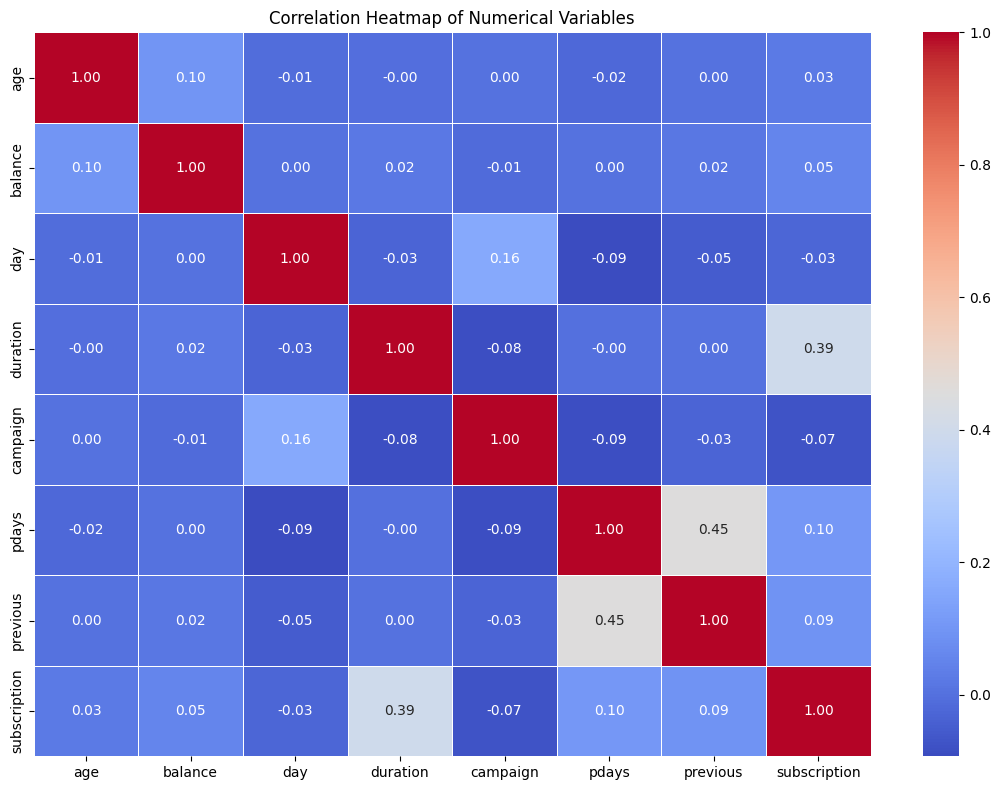

In [53]:
# Correlation Heatmap

corr_df = df.select_dtypes(include='number').copy()

corr_df['subscription'] = df['y'].map({'no': 0, 'yes': 1})

correlation_matrix = corr_df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

### Correlation Analysis

Call duration shows the strongest positive correlation with subscription (0.39). Previous contacts and days since the previous campaign have a moderate correlation (0.45). Most other numerical variables show weak linear relationships with subscription.

In [54]:
#Monthly Subscription Analysis

month_order = [
    'jan', 'feb', 'mar', 'apr', 'may', 'jun',
    'jul', 'aug', 'sep', 'oct', 'nov', 'dec'
]

monthly_analysis = df.groupby('month').agg(
    total_customers=('y', 'count'),
    subscribers=('y', lambda x: (x == 'yes').sum()),
    subscription_rate=('y', lambda x: (x == 'yes').mean() * 100)
).reindex(month_order).reset_index()

display(monthly_analysis.round(2))

,month,total_customers,subscribers,subscription_rate
0,jan,1403,142,10.12
1,feb,2649,441,16.65
2,mar,477,248,51.99
3,apr,2932,577,19.68
4,may,13766,925,6.72
5,jun,5341,546,10.22
6,jul,6895,627,9.09
7,aug,6247,688,11.01
8,sep,579,269,46.46
9,oct,738,323,43.77


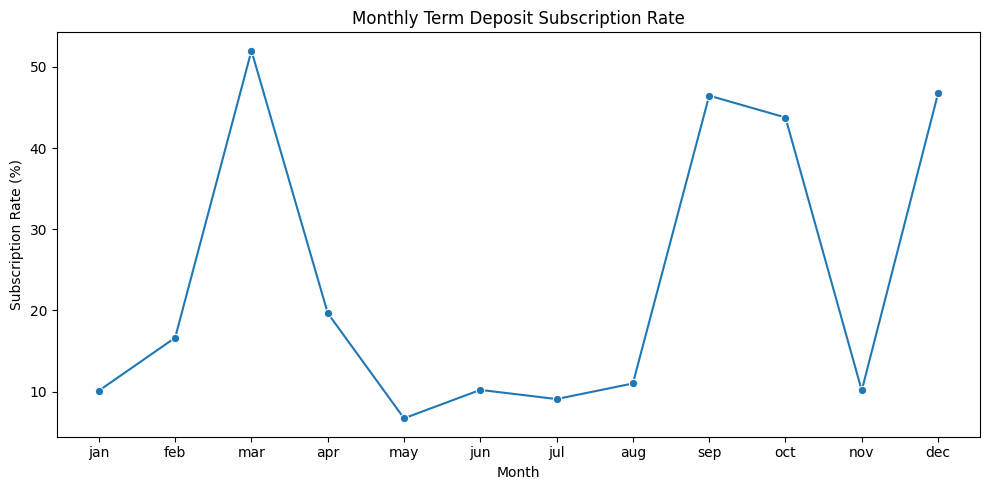

In [55]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_analysis,
    x='month',
    y='subscription_rate',
    marker='o'
)

plt.title('Monthly Term Deposit Subscription Rate')
plt.xlabel('Month')
plt.ylabel('Subscription Rate (%)')
plt.tight_layout()
plt.show()

### Monthly Campaign Performance

March recorded the highest subscription rate (51.99%), followed by December (46.73%) and September (46.46%). May had the lowest rate (6.72%) despite having the highest number of customers contacted. Higher rates in months with fewer observations should be interpreted cautiously.

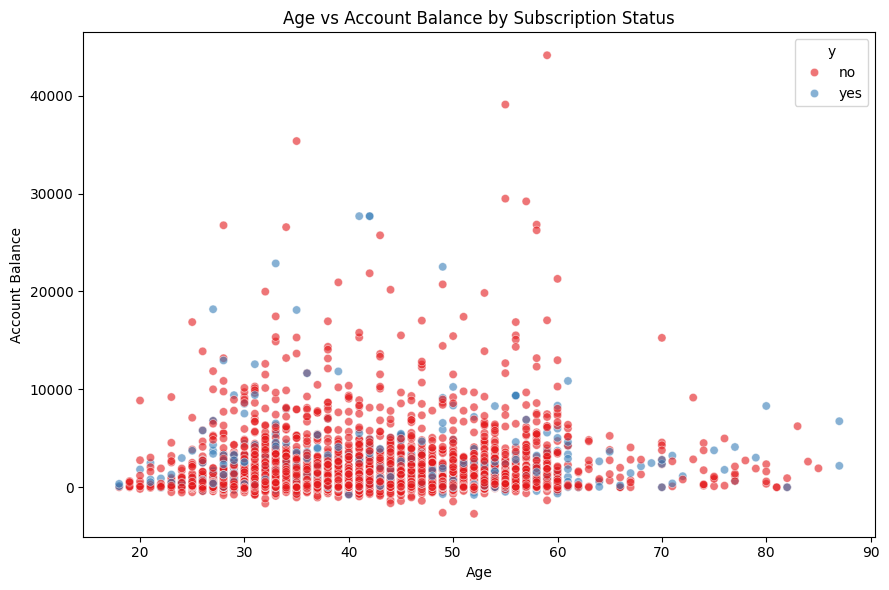

In [56]:
#Age vs Account Balance

sample_df = df.sample(5000, random_state=42)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_df,
    x='age',
    y='balance',
    hue='y',
    alpha=0.6,
    palette='Set1'
)

plt.title('Age vs Account Balance by Subscription Status')
plt.xlabel('Age')
plt.ylabel('Account Balance')
plt.tight_layout()
plt.show()

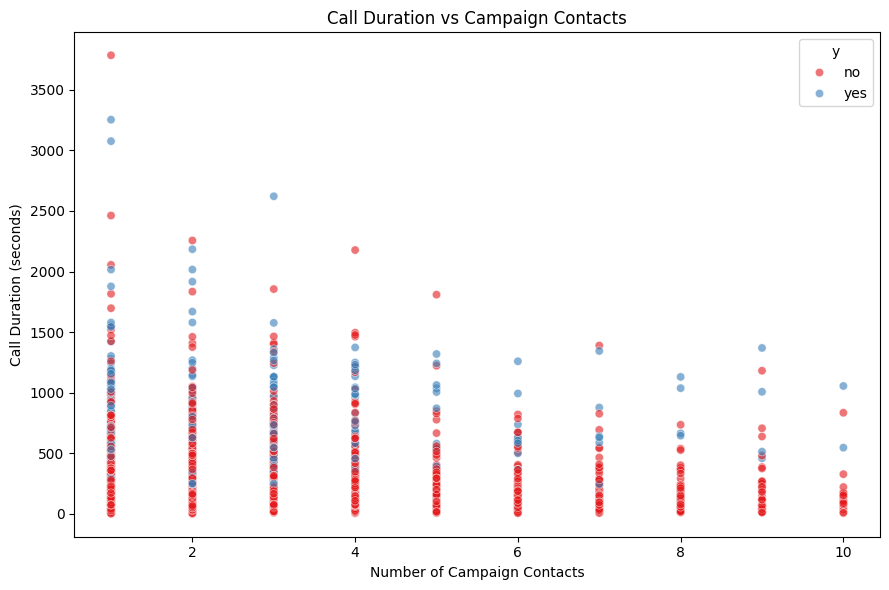

In [57]:
#Call Duration vs Campaign Contacts

plot_df = df[df['campaign'] <= 10].sample(
    n=5000, random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_df,
    x='campaign',
    y='duration',
    hue='y',
    alpha=0.6,
    palette='Set1'
)

plt.title('Call Duration vs Campaign Contacts')
plt.xlabel('Number of Campaign Contacts')
plt.ylabel('Call Duration (seconds)')
plt.tight_layout()
plt.show()

### Scatter Plot Analysis

The age and account balance plot shows no clear relationship between these variables and subscription status. The call duration plot shows that subscribers are more frequently associated with longer calls, suggesting a positive relationship between call duration and subscription.


## Insights and Recommendations

### 1. Business Recommendations

- **Target promising customer segments:** Prioritize retired customers aged 61+ and younger single customers, particularly students, who showed higher subscription rates.
- **Improve contact strategies:** Focus on effective communication through cellular channels and avoid excessive repeated contacts, as subscription rates were lower among frequently contacted customers.
- **Use previous campaign results:** Customers with successful previous campaign outcomes showed a much higher likelihood of subscribing, making them valuable prospects for future campaigns.
- **Optimize campaign timing:** Explore campaign strategies around months with higher observed subscription rates, while considering differences in the number of customers contacted.

### 2. Limitations of the Analysis

- The dataset has an imbalanced target variable, with only 11.70% of customers subscribing.
- Some categorical variables contain `unknown` values, which limit detailed interpretation.
- The analysis identifies associations, not causal relationships.
- Call duration is known only after a call and cannot be used for pre-call customer targeting.
- Monthly subscription rates are based on unequal sample sizes, and the dataset does not provide a year for year-over-year comparisons.

### 3. Conclusion

The analysis identified customer age, job type, previous campaign outcomes, communication method and call duration as useful factors associated with term deposit subscriptions. These findings can help the bank improve customer targeting and campaign planning, although further analysis would be needed to validate the effectiveness of the proposed strategies.
